# Week 10: K-Means, the Elbow Method and the Silhouette Score
**Capstone project:** Predicting Health Risk and Diabetes Status from Lifestyle and Survey Data | Komal Misra

K-means is **unsupervised**: it groups samples into *k* clusters using only their features, with no target. For this project, the question is whether members fall into natural segments that a health program could treat differently, for example one group to send to screening and another to an access program. The diabetes and disease-risk labels are **held out** during clustering and used only afterwards to judge whether the clusters mean anything.

- **Dataset B:** CDC BRFSS 2015 diabetes indicators (21 survey features).
- **Dataset A:** Health & Lifestyle dataset (14 features after holding out `disease_risk`).

**Sections**
1. Setup and data
2. K-means by hand: the fruit example
3. The silhouette score by hand
4. Why k-means uses Euclidean distance
5. Feature scaling
6. The elbow method on the project data
7. The silhouette score on the project data, and a permutation null
8. Are the clusters reproducible?
9. What are the clusters? Profiles and held-out outcomes
10. Summary

## 1. Setup and data

In [ ]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

warnings.filterwarnings('ignore')
SEED = 42
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3})
BLUE, ORANGE, GREEN, VIOLET, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#6250d6', '#8a8984'

In [ ]:
brfss = pd.read_csv('diabetes_012_health_indicators_BRFSS2015.csv')
life = pd.read_csv('health_lifestyle_dataset.csv')
brfss['diabetes'] = (brfss['Diabetes_012'] > 0).astype(int)

# Dataset B: the same 50,000-row stratified sample used in earlier weeks; diabetes held out
XB_all, yB_all = brfss.drop(columns=['Diabetes_012', 'diabetes']), brfss['diabetes']
B, _, yB, _ = train_test_split(XB_all, yB_all, train_size=50_000, stratify=yB_all, random_state=SEED)
B, yB = B.reset_index(drop=True), yB.reset_index(drop=True)

# Dataset A: 50,000 random rows; disease_risk held out; gender encoded 0/1
la = life.drop(columns=['id']).assign(gender=lambda d: (d.gender == 'Male').astype(int)).sample(50_000, random_state=SEED).reset_index(drop=True)
A, riskA = la.drop(columns=['disease_risk']), la['disease_risk']
print('Dataset B:', B.shape, f'(diabetes {yB.mean():.1%}, held out)')
print('Dataset A:', A.shape, f'(disease_risk {riskA.mean():.1%}, held out)')

Dataset B: (50000, 21) (diabetes 15.8%, held out)
Dataset A: (50000, 14) (disease_risk 24.8%, held out)


## 2. K-means by hand: the fruit example
The reading's six fruits, rated 1–5 on four tastes:

In [ ]:
fruit = pd.DataFrame({'sweetness': [4, 1, 5, 3, 5, 3], 'sourness': [2, 5, 1, 4, 2, 3],
                      'bitterness': [1, 2, 1, 3, 1, 2], 'juiciness': [4, 5, 3, 5, 5, 3]},
                     index=['Apple', 'Lemon', 'Banana', 'Grapefruit', 'Mango', 'Blueberry'])
F = fruit.values.astype(float)
fruit

,sweetness,sourness,bitterness,juiciness
Apple,4,2,1,4
Lemon,1,5,2,5
Banana,5,1,1,3
Grapefruit,3,4,3,5
Mango,5,2,1,5
Blueberry,3,3,2,3


K-means alternates two steps until nothing changes:
1. **Assign** each point to its nearest centroid (Euclidean distance).
2. **Update** each centroid to the mean of the points assigned to it.

Starting from the reading's centroids (apple, grapefruit, lemon):

In [ ]:
centroids = fruit.loc[['Apple', 'Grapefruit', 'Lemon']].values.astype(float)
for it in range(1, 10):
    dist = np.sqrt(((F[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2))   # fruits x centroids
    labels = dist.argmin(axis=1)
    new = np.array([F[labels == c].mean(axis=0) for c in range(3)])
    print(f'Iteration {it}:')
    for c in range(3):
        print(f'  cluster {c}: {list(fruit.index[labels == c])}, centroid {np.round(new[c], 2).tolist()}')
    if np.allclose(new, centroids):
        print('Centroids unchanged: converged.'); break
    centroids = new

print(f'\nApple-to-lemon distance: sqrt({((F[0] - F[1]) ** 2).sum():.0f}) = {np.sqrt(((F[0] - F[1]) ** 2).sum()):.3f}')

Iteration 1:
  cluster 0: ['Apple', 'Banana', 'Mango', 'Blueberry'], centroid [4.25, 2.0, 1.25, 3.75]
  cluster 1: ['Grapefruit'], centroid [3.0, 4.0, 3.0, 5.0]
  cluster 2: ['Lemon'], centroid [1.0, 5.0, 2.0, 5.0]
Iteration 2:
  cluster 0: ['Apple', 'Banana', 'Mango', 'Blueberry'], centroid [4.25, 2.0, 1.25, 3.75]
  cluster 1: ['Grapefruit'], centroid [3.0, 4.0, 3.0, 5.0]
  cluster 2: ['Lemon'], centroid [1.0, 5.0, 2.0, 5.0]
Centroids unchanged: converged.

Apple-to-lemon distance: sqrt(20) = 4.472


This matches the reading: apple, banana, mango and blueberry form one cluster with centroid (4.25, 2, 1.25, 3.75), and the lemon and grapefruit each stay alone. After the centroid moves, no fruit switches clusters, so the algorithm stops.

**Within-cluster sum of squares (WCSS)**, also called inertia, adds up each point's squared distance to its own centroid:

In [ ]:
wcss_by_fruit = ((F - centroids[labels]) ** 2).sum(axis=1)
print(pd.Series(wcss_by_fruit, index=fruit.index, name='squared distance to own centroid').round(4).to_string())
print(f'\nTotal WCSS = {wcss_by_fruit.sum():.4f}')

Apple         0.1875
Lemon         0.0000
Banana        2.1875
Grapefruit    0.0000
Mango         2.1875
Blueberry     3.6875

Total WCSS = 8.2500


The apple contributes 0.1875, as in the reading. Repeating this for k = 1 to 6 (letting scikit-learn pick the best of many random starts) gives the elbow plot:

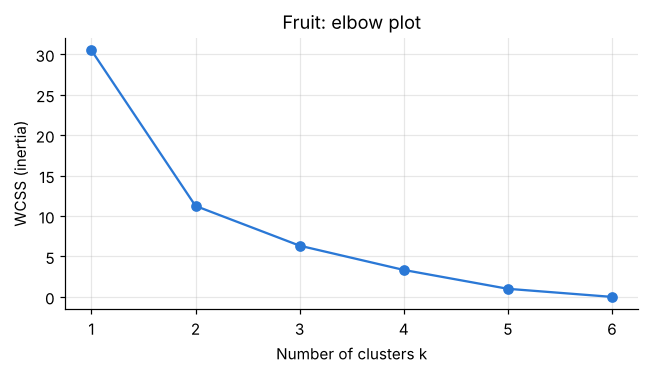

k,1,2,3,4,5,6
WCSS,30.5,11.25,6.333,3.333,1.0,0.0


In [ ]:
ks_f = range(1, 7)
inertia_f = [KMeans(k, n_init=50, random_state=SEED).fit(F).inertia_ for k in ks_f]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ks_f, inertia_f, marker='o', color=BLUE)
ax.set_xlabel('Number of clusters k'); ax.set_ylabel('WCSS (inertia)'); ax.set_title('Fruit: elbow plot')
plt.tight_layout(); plt.show()
pd.Series(inertia_f, index=pd.Index(ks_f, name='k'), name='WCSS').round(3).to_frame().T

WCSS always falls as *k* grows and reaches exactly 0 at k = 6, when every fruit is its own centroid. That is why WCSS alone cannot choose *k*: it would always pick the largest *k*. The elbow method looks instead for the point where adding a cluster stops paying off. Here the drop from k = 1 to k = 2 is much larger than any later drop, so the elbow is at **k = 2**, roughly sweet fruits vs. sour ones:

In [ ]:
km2 = KMeans(2, n_init=50, random_state=SEED).fit(F)
for c in range(2):
    print(f'cluster {c}: {list(fruit.index[km2.labels_ == c])}')

cluster 0: ['Lemon', 'Grapefruit']
cluster 1: ['Apple', 'Banana', 'Mango', 'Blueberry']


## 3. The silhouette score by hand
For each point *i*:
- $a(i)$ = mean distance to the **other** points in its own cluster (intra-cluster distance)
- $b(i)$ = mean distance to the points in the **nearest other** cluster (inter-cluster distance)
- $s(i) = \dfrac{b(i) - a(i)}{\max(a(i), b(i))}$, defined as 0 if the point is alone in its cluster.

Scores near 1 mean the point sits well inside its cluster, near 0 mean it is on a boundary, and negative values mean it is closer to another cluster. The overall score is the mean of $s(i)$. Computing it directly for the fruit clusters:

In [ ]:
def silhouette_by_hand(X, labels):
    D = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))
    s = np.zeros(len(X))
    for i in range(len(X)):
        own = (labels == labels[i]); own[i] = False
        if own.sum() == 0:
            continue                                   # singleton cluster: s = 0
        a = D[i, own].mean()
        b = min(D[i, labels == c].mean() for c in set(labels) if c != labels[i])
        s[i] = (b - a) / max(a, b)
    return s

rows = []
for k in range(2, 6):
    lab = KMeans(k, n_init=50, random_state=SEED).fit_predict(F)
    s = silhouette_by_hand(F, lab)
    rows.append({'k': k, 'silhouette (by hand)': s.mean(), 'silhouette (scikit-learn)': silhouette_score(F, lab)})
pd.DataFrame(rows).set_index('k').round(4)

,silhouette (by hand),silhouette (scikit-learn)
k,,
2,0.4058,0.4058
3,0.2113,0.2113
4,0.1625,0.1625
5,0.0918,0.0918


The hand calculation matches scikit-learn exactly. Silhouette is highest at **k = 2**, agreeing with the elbow. Note the cost: silhouette needs the distance between **every pair** of points, so its cost grows with the square of the sample size, while WCSS needs only each point's distance to its own centroid. Section 7 measures that difference on the project data.

## 4. Why k-means uses Euclidean distance
The update step sets each centroid to the **mean** of its points. The mean is the point that minimizes the sum of *squared Euclidean* distances, so both steps of k-means reduce the same quantity (WCSS), and the algorithm is guaranteed to converge. With a different metric, the mean is no longer the best center, so the update step can make things worse. The reading's example: points (1, 1), (1, −1), (−2, 0).

In [ ]:
pts = np.array([[1, 1], [1, -1], [-2, 0]], dtype=float)
def sq_euclid(c): return ((pts - c) ** 2).sum()
def manhattan(c): return np.abs(pts - c).sum()

table = pd.DataFrame({'sum of squared Euclidean': [sq_euclid(c) for c in [(0, 0), (1, 0)]],
                      'sum of Manhattan': [manhattan(c) for c in [(0, 0), (1, 0)]]},
                     index=['mean (0, 0)', 'median (1, 0)'])
grid = np.array([[x, y] for x in np.linspace(-2, 2, 81) for y in np.linspace(-2, 2, 81)])
print('Best center on a fine grid, squared Euclidean:', grid[np.argmin([sq_euclid(c) for c in grid])].round(2))
print('Best center on a fine grid, Manhattan:        ', grid[np.argmin([manhattan(c) for c in grid])].round(2))
table

Best center on a fine grid, squared Euclidean: [0. 0.]
Best center on a fine grid, Manhattan:         [1. 0.]


,sum of squared Euclidean,sum of Manhattan
"mean (0, 0)",8.0,6.0
"median (1, 0)",11.0,5.0


The mean (0, 0) is the best center under squared Euclidean distance (sum = 8). Under Manhattan distance the best center is the coordinate-wise **median** (1, 0), with a sum of 5 instead of 6. A Manhattan version of the algorithm exists, *k-medians*, but it is a different method. K-means is defined by Euclidean distance and the mean.

This matters for the project data. In Week 8, Manhattan distance worked best for KNN on BRFSS. K-means cannot use it, so it inherits Euclidean distance's sensitivity to single large differences, which shows up in Section 7.

## 5. Feature scaling
K-means uses raw Euclidean distance, so a feature with large numbers dominates. The reading's example: two houses that differ by $100 in price and by two bedrooms.

In [ ]:
houses = np.array([[300_000, 1], [300_100, 3]], dtype=float)
d = houses[1] - houses[0]
print(f'Unscaled squared differences: price {d[0]**2:,.0f}, bedrooms {d[1]**2:.0f}')

Unscaled squared differences: price 10,000, bedrooms 4


Unscaled, the $100 price gap counts 2,500 times as much as the two-bedroom gap. Dataset A has the same problem: `daily_steps` has a standard deviation of about 5,500, while most features are below 50. Here is what unscaled k-means finds:

In [ ]:
km_raw = KMeans(3, n_init=10, random_state=SEED).fit(A)
km_scl = KMeans(3, n_init=10, random_state=SEED).fit(StandardScaler().fit_transform(A))

def spread(labels):   # how far apart the cluster means are, in standard deviations of each feature
    m = A.groupby(labels).mean()
    return ((m.max() - m.min()) / A.std()).round(2)
pd.DataFrame({'unscaled k-means': spread(km_raw.labels_), 'scaled k-means': spread(km_scl.labels_)}) \
  .sort_values('unscaled k-means', ascending=False).head(6) \
  .rename_axis('range of cluster means (in SDs)')

,unscaled k-means,scaled k-means
range of cluster means (in SDs),,
daily_steps,2.31,0.00
age,0.03,0.00
water_intake_l,0.03,0.02
diastolic_bp,0.02,0.03
resting_hr,0.02,0.01
smoker,0.02,2.50


In [ ]:
A.groupby(km_raw.labels_)['daily_steps'].agg(['count', 'min', 'max']).rename_axis('unscaled cluster')

,count,min,max
unscaled cluster,,,
0,16555,1000,7281
1,16663,13633,19999
2,16782,7280,13633


Unscaled, the three clusters are simply low, medium and high step counts: the clusters differ by more than 2 standard deviations in `daily_steps` and almost nothing in anything else. After converting every feature to a z-score, all features can influence the clustering. Everything from here on uses standardized features.

In [ ]:
ZA = StandardScaler().fit_transform(A)
ZB = StandardScaler().fit_transform(B)

## 6. The elbow method on the project data

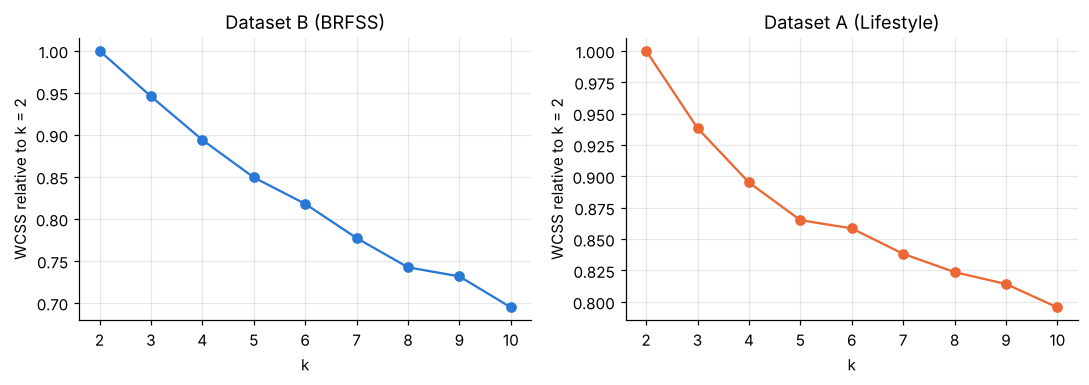

Elbow curves for both datasets: 7s


% of WCSS(k=2) removed,2->3,3->4,4->5,5->6,6->7,7->8,8->9,9->10
Dataset B (BRFSS),5.4,5.2,4.5,3.1,4.1,3.5,1.1,3.7
Dataset A (Lifestyle),6.2,4.3,3.0,0.7,2.0,1.5,0.9,1.9


In [ ]:
ks = list(range(2, 11))
t0 = time.time()
inertia = {name: [KMeans(k, n_init=10, random_state=SEED).fit(Z).inertia_ for k in ks]
           for name, Z in [('Dataset B (BRFSS)', ZB), ('Dataset A (Lifestyle)', ZA)]}
elbow_time = time.time() - t0
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (name, v), c in zip(axes, inertia.items(), [BLUE, ORANGE]):
    ax.plot(ks, np.array(v) / v[0], marker='o', color=c)
    ax.set_title(name); ax.set_xlabel('k'); ax.set_ylabel('WCSS relative to k = 2')
plt.tight_layout(); plt.show()
print(f'Elbow curves for both datasets: {elbow_time:.0f}s')
pd.DataFrame({n: -np.diff(v) / v[0] * 100 for n, v in inertia.items()},
             index=[f'{a}->{b}' for a, b in zip(ks[:-1], ks[1:])]).round(1).rename_axis('% of WCSS(k=2) removed').T

Neither curve has a clear elbow. Each added cluster removes only about 1–6% of the k = 2 WCSS, with no large early drop followed by a flat tail, so there is no point where the curve bends sharply. On real, high-dimensional data this is common: the elbow method works well when clusters are compact and well separated, as with the fruit, and is ambiguous otherwise. It cannot tell us how many clusters there are, or whether there are any at all. The silhouette score is the next tool.

## 7. The silhouette score on the project data, and a permutation null
Silhouette needs all pairwise distances, so on 50,000 rows it is expensive. First, the cost:

In [ ]:
lab = KMeans(4, n_init=10, random_state=SEED).fit_predict(ZB)
for n in [2000, 8000]:
    t0 = time.time(); s = silhouette_score(ZB, lab, sample_size=n, random_state=SEED)
    print(f'silhouette on a {n:>5,}-row sample: {s:.4f} in {time.time()-t0:.2f}s')
print(f'Pairwise distances for all 50,000 rows: {50_000**2/2:,.0f}  (vs. 50,000 x 4 = 200,000 for WCSS)')

silhouette on a 2,000-row sample: 0.0854 in 0.04s


silhouette on a 8,000-row sample: 0.0894 in 0.80s
Pairwise distances for all 50,000 rows: 1,250,000,000  (vs. 50,000 x 4 = 200,000 for WCSS)


Quadrupling the sample multiplies the time by roughly 20 (about 16 expected from the number of pairs, plus overhead), while the score barely changes. I use an 8,000-row sample for every silhouette score below.

Silhouette values on real data are often low, roughly 0.05–0.25, and it is hard to say whether a given value means real structure. To give it a reference point, I build a **permutation null** for each dataset: each column is shuffled independently. This keeps every feature's distribution, including how many respondents answered yes to each question, but destroys any relationship between features. If the real data's silhouette is no better than its shuffled copy's, the clusters are an artifact of the feature distributions, not real groups of people.

38s


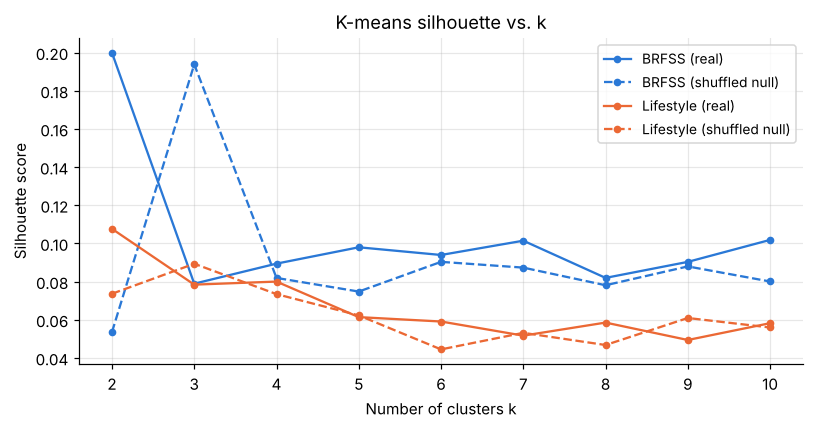

k,2,3,4,5,6,7,8,9,10
B,0.200,0.079,0.089,0.098,0.094,0.101,0.082,0.090,0.102
B_null,0.054,0.194,0.082,0.075,0.090,0.087,0.078,0.088,0.080
A,0.108,0.078,0.080,0.061,0.059,0.052,0.058,0.049,0.058
A_null,0.074,0.089,0.073,0.062,0.044,0.053,0.047,0.061,0.056


In [ ]:
rng = np.random.default_rng(SEED)
def permute(df):
    return pd.DataFrame({c: rng.permutation(df[c].values) for c in df.columns})
A_null, B_null = permute(A), permute(B)
Z = {'B': ZB, 'B_null': StandardScaler().fit_transform(B_null), 'A': ZA, 'A_null': StandardScaler().fit_transform(A_null)}

t0 = time.time()
sil = {name: [silhouette_score(z, KMeans(k, n_init=10, random_state=SEED).fit_predict(z), sample_size=8000, random_state=SEED)
              for k in ks] for name, z in Z.items()}
print(f'{time.time()-t0:.0f}s')

fig, ax = plt.subplots(figsize=(7.5, 4))
for name, lab_, c, ls in [('B', 'BRFSS (real)', BLUE, '-'), ('B_null', 'BRFSS (shuffled null)', BLUE, '--'),
                          ('A', 'Lifestyle (real)', ORANGE, '-'), ('A_null', 'Lifestyle (shuffled null)', ORANGE, '--')]:
    ax.plot(ks, sil[name], marker='o', ms=4, color=c, ls=ls, label=lab_)
ax.set_xlabel('Number of clusters k'); ax.set_ylabel('Silhouette score'); ax.set_title('K-means silhouette vs. k')
ax.legend(fontsize=9); plt.tight_layout(); plt.show()
pd.DataFrame(sil, index=pd.Index(ks, name='k')).round(3).T

Taken alone, the BRFSS curve suggests **k = 2** (silhouette 0.20). But the shuffled BRFSS data reaches almost the same value at k = 3 (0.19), and the Lifestyle curve sits on top of its shuffled null at every *k*. Silhouette alone cannot separate real structure from noise here.

Why does data with no structure score so well? BRFSS has several rare yes/no answers. After standardizing, the roughly 4–5% of respondents with no cholesterol check or no health coverage sit about 4–5 standard deviations from everyone else. K-means separates them into small, distant groups, and silhouette rewards distant groups whether or not they mean anything (scaling does not remove outliers, as Week 8 showed). A silhouette diagram, which plots every point's score sorted within its cluster, shows how differently the same average can arise:

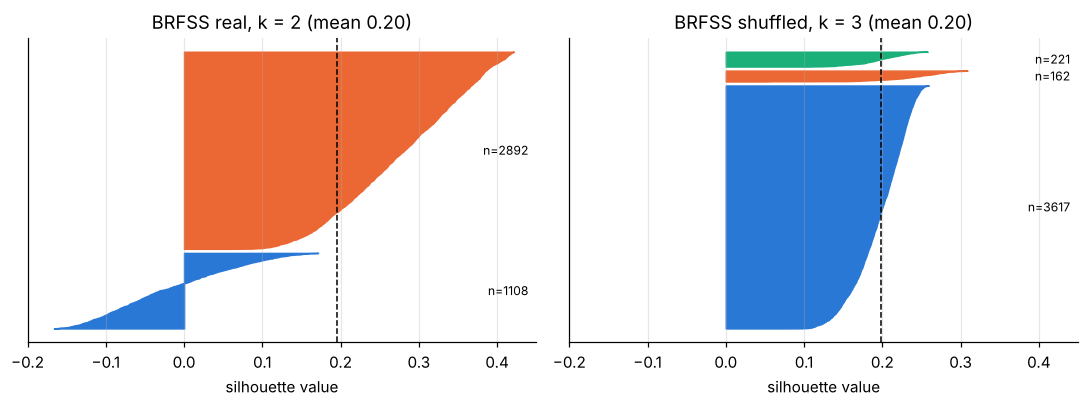

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
idx = np.random.default_rng(SEED).choice(len(ZB), 4000, replace=False)
for ax, (name, z, k) in zip(axes, [('BRFSS real, k = 2', Z['B'], 2), ('BRFSS shuffled, k = 3', Z['B_null'], 3)]):
    lab_ = KMeans(k, n_init=10, random_state=SEED).fit_predict(z)[idx]
    s = silhouette_samples(z[idx], lab_); y0 = 0
    for c, col in zip(range(k), [BLUE, ORANGE, GREEN]):
        v = np.sort(s[lab_ == c]); ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=col)
        ax.text(0.44, y0 + len(v) / 2, f'n={len(v)}', fontsize=8, va='center', ha='right'); y0 += len(v) + 60
    ax.axvline(s.mean(), color='black', ls='--', lw=1); ax.set_title(f'{name} (mean {s.mean():.2f})')
    ax.set_xlabel('silhouette value'); ax.set_yticks([]); ax.set_xlim(-0.2, 0.45)
plt.tight_layout(); plt.show()

Both have a mean of 0.20, for opposite reasons. In the **shuffled** data, two tiny clusters of outliers sit far from everyone else, so almost every point is much closer to its own cluster than to the next one, and nearly all scores are positive. The separation is real geometrically but means nothing. In the **real** data, the larger, healthier cluster scores well, but many members of the smaller, less healthy cluster score **below zero**: they are closer to the healthy cluster's members on average than to their own. That cluster is a diffuse tail of worse health rather than a separate island, which is what a gradient of risk in a population looks like. A single average hides both stories. Silhouette is a useful guide, but it needs a reference point and other checks.

## 8. Are the clusters reproducible?
A real segment should appear again in new data from the same population. I split each dataset into two random halves, cluster each half separately, assign the second half to the first half's centroids, and compare the two labelings with the **adjusted Rand index** (ARI: 1 = identical groupings, 0 = no better than chance). This is the clustering equivalent of checking a model on held-out data.

3s


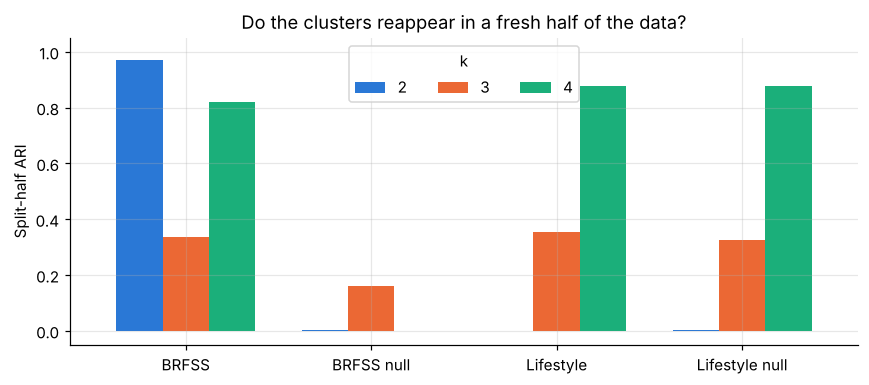

,BRFSS,BRFSS null,Lifestyle,Lifestyle null
k,,,,
2,0.972,0.002,-0.002,0.002
3,0.335,0.161,0.356,0.326
4,0.822,0.001,0.877,0.876


In [ ]:
def split_half_ari(z, k):
    idx = rng.permutation(len(z)); h1, h2 = idx[:len(z) // 2], idx[len(z) // 2:]
    m1 = KMeans(k, n_init=10, random_state=SEED).fit(z[h1]); m2 = KMeans(k, n_init=10, random_state=SEED).fit(z[h2])
    return adjusted_rand_score(m1.predict(z[h2]), m2.labels_)

t0 = time.time()
order = ['A', 'B', 'A_null', 'B_null']          # same order of random splits as the Milestone 2 analysis script
ari = pd.DataFrame({name: {k: split_half_ari(Z[name], k) for k in [2, 3, 4]} for name in order})[['B', 'B_null', 'A', 'A_null']]
print(f'{time.time()-t0:.0f}s')
ari.index.name = 'k'
ari.columns = ['BRFSS', 'BRFSS null', 'Lifestyle', 'Lifestyle null']
ax = ari.T.plot.bar(figsize=(8, 3.6), color=[BLUE, ORANGE, GREEN], width=0.75, rot=0)
ax.set_ylabel('Split-half ARI'); ax.set_ylim(-0.05, 1.05); ax.legend(title='k', ncol=3); ax.set_title('Do the clusters reappear in a fresh half of the data?')
plt.tight_layout(); plt.show()
ari.round(3)

For BRFSS, the k = 2 clusters reappear almost exactly in a fresh half (ARI 0.97), while the shuffled copy's do not (0.002). That is strong evidence the BRFSS split is real.

The Lifestyle results show this test has a blind spot too: at k = 4, the real data and its shuffled copy are **equally** reproducible (about 0.88). Dataset A has four yes/no columns (gender, smoker, alcohol, family history), and k-means can split on those in exactly the same way in any sample, real or shuffled. Reproducible is not the same as meaningful. The last check is whether the clusters say anything about the outcome that was held out.

## 9. What are the clusters? Profiles and held-out outcomes
### Dataset A

In [ ]:
kmA = KMeans(3, n_init=10, random_state=SEED).fit(ZA)
centA = pd.DataFrame(kmA.cluster_centers_, columns=A.columns).round(2)
centA.insert(0, 'size', np.bincount(kmA.labels_))
centA['disease_risk (held out)'] = riskA.groupby(kmA.labels_).mean().round(3).values
centA.rename_axis('cluster (centroids in SDs)')

,size,age,gender,bmi,daily_steps,sleep_hours,water_intake_l,calories_consumed,smoker,alcohol,resting_hr,systolic_bp,diastolic_bp,cholesterol,family_history,disease_risk (held out)
cluster (centroids in SDs),,,,,,,,,,,,,,,,
0,9972,-0.0,-0.01,-0.01,0.0,-0.02,-0.00,0.01,2.0,0.0,-0.01,0.02,-0.02,0.0,-0.00,0.253
1,19944,0.0,-1.00,0.00,-0.0,0.01,0.01,0.01,-0.5,0.0,0.00,-0.00,-0.00,-0.0,-0.01,0.247
2,20084,-0.0,1.00,0.00,-0.0,-0.00,-0.01,-0.01,-0.5,-0.0,0.00,-0.01,0.01,0.0,0.01,0.247


The Lifestyle clusters are smokers, female non-smokers and male non-smokers. Every continuous feature (age, BMI, blood pressure, steps and the rest) has a centroid within ±0.02 standard deviations of the mean in every cluster, so k-means has simply re-cut the yes/no columns. Disease risk is 25.3%, 24.7% and 24.7%: the clusters carry no information about the outcome. Together with Sections 7 and 8, this confirms the result from earlier weeks: Dataset A has no structure to find.

### Dataset B

In [ ]:
profile_cols = ['GenHlth', 'PhysHlth', 'DiffWalk', 'BMI', 'HighBP', 'HighChol', 'HeartDiseaseorAttack', 'Age',
                'Income', 'AnyHealthcare', 'NoDocbcCost', 'PhysActivity']
def profile(k):
    lab_ = KMeans(k, n_init=10, random_state=SEED).fit_predict(ZB)
    p = B.groupby(lab_)[profile_cols].mean()
    p.insert(0, 'diabetes (held out)', yB.groupby(lab_).mean()); p.insert(0, 'size', np.bincount(lab_))
    return p.sort_values('diabetes (held out)')
profile(2).round(2)

,size,diabetes (held out),GenHlth,PhysHlth,DiffWalk,BMI,HighBP,HighChol,HeartDiseaseorAttack,Age,Income,AnyHealthcare,NoDocbcCost,PhysActivity
1,36503,0.09,2.11,1.30,0.02,27.39,0.32,0.35,0.03,7.58,6.70,0.96,0.05,0.85
0,13497,0.33,3.59,12.24,0.56,30.88,0.72,0.63,0.26,9.29,4.36,0.93,0.18,0.50


At k = 2, BRFSS splits into a healthier majority and a less healthy third: worse self-rated health, about 12 bad physical-health days a month vs. 1, much more difficulty walking, more high blood pressure and heart disease, and lower income. Diabetes, which k-means never saw, is **33%** in the second group vs. **9%** in the first. k = 2 has the best silhouette and reproducibility; k = 4 is less stable (ARI 0.82) but more useful for a program:

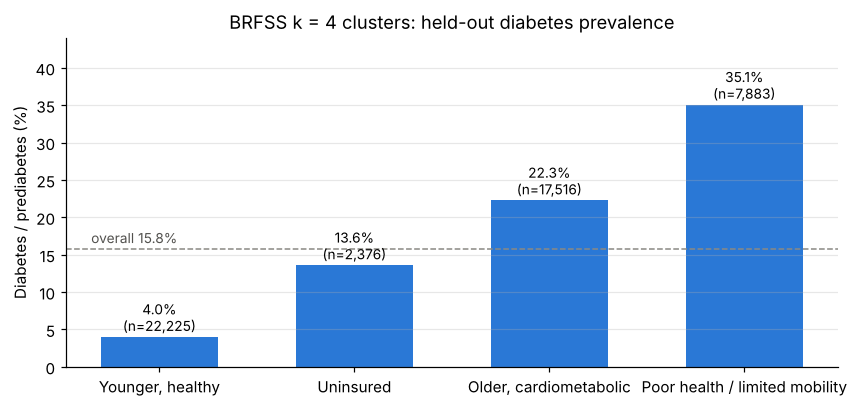

,size,diabetes (held out),GenHlth,PhysHlth,DiffWalk,BMI,HighBP,HighChol,HeartDiseaseorAttack,Age,Income,AnyHealthcare,NoDocbcCost,PhysActivity
"Younger, healthy",22225,0.040,1.944,1.390,0.022,26.555,0.069,0.200,0.009,6.555,6.948,1.000,0.052,0.882
Uninsured,2376,0.136,2.682,4.328,0.158,28.789,0.339,0.340,0.065,6.147,4.623,0.000,0.372,0.692
"Older, cardiometabolic",17516,0.223,2.586,1.739,0.085,29.255,0.783,0.649,0.122,9.666,5.997,1.000,0.040,0.737
Poor health / limited mobility,7883,0.351,3.897,17.876,0.779,31.151,0.676,0.598,0.281,9.181,4.168,0.996,0.185,0.467


In [ ]:
p4 = profile(4)
names = {}
for c, r in p4.iterrows():
    names[c] = ('Uninsured' if r['AnyHealthcare'] < 0.5 else
                'Poor health / limited mobility' if r['DiffWalk'] > 0.5 else
                'Older, cardiometabolic' if r['HighBP'] > 0.5 else 'Younger, healthy')
p4.index = [names[c] for c in p4.index]
fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(p4.index, p4['diabetes (held out)'] * 100, color=BLUE, width=0.6)
for b, (n, v) in zip(bars, zip(p4['size'], p4['diabetes (held out)'])):
    ax.text(b.get_x() + b.get_width() / 2, v * 100 + 0.8, f'{v:.1%}\n(n={n:,})', ha='center', fontsize=9)
ax.axhline(yB.mean() * 100, color=GRAY, ls='--', lw=1); ax.text(-0.35, yB.mean() * 100 + 0.8, f'overall {yB.mean():.1%}', fontsize=9, color='#52514e')
ax.set_ylabel('Diabetes / prediabetes (%)'); ax.set_ylim(0, 44); ax.set_title('BRFSS k = 4 clusters: held-out diabetes prevalence')
ax.grid(axis='x', visible=False); plt.tight_layout(); plt.show()
p4.round(3)

The four BRFSS clusters, formed without any diabetes information, range from **4.0% to 35.1%** prevalence, a ninefold spread. Each one suggests a different kind of outreach:
- **Younger, healthy:** low risk; no targeted action.
- **Uninsured:** no one in this cluster has coverage, and 37% skipped a doctor because of cost. Risk is moderate, but the barrier is access, which a risk score alone would not reveal.
- **Older, cardiometabolic:** high blood pressure and cholesterol are common; a natural group for screening and medication follow-up.
- **Poor health / limited mobility:** highest risk, with about 18 bad physical-health days a month and most reporting difficulty walking; coaching would need to account for limited mobility.

This is where clustering adds something the supervised models in Weeks 8 and 9 did not: not just *who* is at risk, but *which kind* of intervention fits each group.

## 10. Summary
| Topic | Finding |
|---|---|
| K-means by hand | Reproduced the fruit example: converges after one update to {apple, banana, mango, blueberry}, {lemon}, {grapefruit}; the apple's WCSS contribution is 0.1875. |
| Elbow method | Clear elbow at k = 2 for the fruit. No clear elbow on either project dataset: WCSS falls smoothly. |
| Silhouette score | Hand calculation matches scikit-learn. Cost grows with the square of the sample size, so it is computed on an 8,000-row sample. |
| Euclidean distance | The mean minimizes squared Euclidean distance (sum 8); under Manhattan, the median (1, 0) beats the mean (5 vs. 6), so k-means is tied to Euclidean distance. |
| Feature scaling | Unscaled, Dataset A's clusters are just step-count bands. Scaling lets every feature count. |
| Permutation null | Shuffled BRFSS scores a silhouette almost as high as real BRFSS (0.19 vs. 0.20), because rare yes/no answers become extreme outliers after scaling. Silhouette alone is not proof of structure. |
| Reproducibility | BRFSS k = 2 split-half ARI 0.97 vs. 0.002 for its null. Lifestyle clusters are as reproducible as their null at k = 4, because both split the same yes/no columns. |
| Held-out outcomes | BRFSS k = 4 clusters range from 4.0% to 35.1% diabetes. Lifestyle clusters are flat at about 25% disease risk. |

K-means is useful when the goal is to **segment** a population rather than predict one outcome, and when no labels exist to train on. The elbow method is cheap and works when clusters are well separated. The silhouette score is more informative but costs much more, and on real data both need extra checks (a shuffled null, reproducibility and outcome profiles) before the clusters can be trusted.

**Sources:** Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65; Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193–218; Tibshirani, R., Walther, G., & Hastie, T. (2001). Estimating the number of clusters in a data set via the gap statistic. *JRSS B, 63*(2); scikit-learn User Guide, *Clustering: K-means* (https://scikit-learn.org/stable/modules/clustering.html#k-means).